# RepSeq BCR (IGH) Analysis

 MiXCR обработали парные FASTQ пресетом `milab-human-rna-ig-umi-multiplex` . Потом анализ как в семинаре

## Imports

In [2]:
# Импортируем библиотеки, которые потребуются для таблиц, расчёта метрик и графиков.
import pandas as pd
from pandas.api.types import CategoricalDtype
import os

from repseq import clonosets as cl
from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import clustering
from repseq import beta
from pathlib import Path
import shutil

## WORKING DIR

In [ ]:
SAMPLE_ID = 'DChu_T7_pbmc_d7COVID2_2'
FASTQ_DIR = Path.cwd() / 'data'  
RESULTS_DIR = Path("../outputs/bcr")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)



R1 = FASTQ_DIR / f'{SAMPLE_ID}_R1.fastq'
R2 = FASTQ_DIR / f'{SAMPLE_ID}_R2.fastq'
PREFIX = RESULTS_DIR / SAMPLE_ID
IGH_TABLE = RESULTS_DIR / f'{SAMPLE_ID}.clonotypes.IGH.txt'
FASTQ_DIR = Path.cwd() / "data" / "bcr_raw"
MIXCR_DIR = Path.cwd() / "outputs" / "bcr"
CLNS_FILE = MIXCR_DIR / f"{SAMPLE_ID}.clns"
RAW_EXPORT = MIXCR_DIR / f"{SAMPLE_ID}.export.IGH.tsv"
IGH_TABLE = MIXCR_DIR / f"{SAMPLE_ID}.clonotypes.IGH.txt"

WORKING_DIR = str(Path.cwd() / "outputs" / "repseq_bcr")

print('R1:', R1, '| найден:', R1.exists())
print('R2:', R2, '| найден:', R2.exists())
print('MiXCR:', shutil.which('mixcr'))
print('Output:', RESULTS_DIR)


R1: /home/khokholmongolll/algo/bioinf/hw_bioinformatics/hw_immunogenetics/data/DChu_T7_pbmc_d7COVID2_2_R1.fastq | найден: True
R2: /home/khokholmongolll/algo/bioinf/hw_bioinformatics/hw_immunogenetics/data/DChu_T7_pbmc_d7COVID2_2_R2.fastq | найден: True
MiXCR: /home/khokholmongolll/miniconda3/envs/immune-mixcr/bin/mixcr
Output: ../outputs/bcr


## MiXCR

In [ ]:
!mkdir -p /outputs/bcr

!mixcr analyze milab-human-rna-ig-umi-multiplex \
    data/DChu_T7_pbmc_d7COVID2_2_R1.fastq \
    data/DChu_T7_pbmc_d7COVID2_2_R2.fastq \
    /outputs/bcr/DChu_T7_pbmc_d7COVID2_2

In [ ]:

!test -s "{RAW_EXPORT}" || mixcr exportClones --chains IGH -uniqueTagCount Molecule "{CLNS_FILE}" "{RAW_EXPORT}"
!ls -lh "{RAW_EXPORT}"

-rw-rw-r-- 1 khokholmongolll khokholmongolll 48M Nov 23 20:41 /home/khokholmongolll/algo/bioinf/hw_bioinformatics/hw_immunogenetics/outputs/bcr/DChu_T7_pbmc_d7COVID2_2.export.IGH.tsv


## Готовим MiXCR-таблицу для repseq

In [ ]:

raw_clones = pd.read_csv(RAW_EXPORT, sep="\t")
if "uniqueUMICount" not in raw_clones.columns:
    for col in ("uniqueTagCountMolecule", "uniqueMoleculeCount"):
        if col in raw_clones.columns:
            raw_clones.rename(columns={col: "uniqueUMICount"}, inplace=True)
            break

required = {"nSeqCDR3", "aaSeqCDR3", "allVHitsWithScore", "allJHitsWithScore", "uniqueUMICount"}
missing = required - set(raw_clones.columns)
if missing:
    raise ValueError(f"Не хватает столбцов для repseq: {missing}")
raw_clones["uniqueUMICount"] = pd.to_numeric(raw_clones["uniqueUMICount"], errors="raise").astype("Int64")
if raw_clones["uniqueUMICount"].isna().any():
    raise ValueError("UMI-счётчики содержат пропуски")
raw_clones["uniqueUMIFraction"] = (raw_clones["uniqueUMICount"] / raw_clones["uniqueUMICount"].sum()).astype(float)


if "cloneCount" in raw_clones.columns:
    read_weights = pd.to_numeric(raw_clones["cloneCount"], errors="raise")
    if not read_weights.dropna().mod(1).eq(0).all():
        raw_clones["mixcrWeightedCloneCount"] = read_weights
        raw_clones["cloneCount"] = read_weights.round().astype("Int64")
        print("Внимание: взвешенный cloneCount округлён для чтения repseq; аналитика по UMI")

raw_clones.to_csv(IGH_TABLE, sep="\t", index=False)
print("IGH-таблица:", IGH_TABLE)
print("Число клонотипов:", len(raw_clones))
print("Сумма UMI:", int(raw_clones["uniqueUMICount"].sum()))
raw_clones[["aaSeqCDR3", "nSeqCDR3", "uniqueUMICount", "allVHitsWithScore", "allJHitsWithScore"]].head()

IGH-таблица: /home/khokholmongolll/algo/bioinf/hw_bioinformatics/hw_immunogenetics/outputs/bcr/DChu_T7_pbmc_d7COVID2_2.clonotypes.IGH.txt
Число клонотипов: 37516
Сумма UMI: 90924


,aaSeqCDR3,nSeqCDR3,uniqueUMICount,allVHitsWithScore,allJHitsWithScore
0,CAHSPASQGHFLMTFGGLIIPHFDSW,TGTGCACACAGCCCCGCCTCACAGGGTCATTTTTTGATGACATTTG...,445,IGHV2-5*00(1927.1),IGHJ4*00(417.6)
1,CARDRRTGLWSGYGYMDVW,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,645,IGHV3-33*00(1820.8),IGHJ6*00(368.1)
2,CAHSSDIIGGSWGFGMDVW,TGTGCGCACAGTTCGGATATAATTGGAGGTTCATGGGGATTTGGAA...,255,IGHV2-5*00(1921.9),IGHJ6*00(368.3)
3,CARDPNYDFWSGGDMNVW,TGTGCGAGAGACCCCAATTACGATTTTTGGAGTGGAGGGGACATGA...,353,IGHV3-21*00(2230.9),IGHJ6*00(367.1)
4,CTTDLDYYDSSGYRFDCW,TGTACCACAGATTTAGATTACTATGATAGTAGTGGTTATCGCTTTG...,339,IGHV3-15*00(2085),IGHJ4*00(406.9)


## Read clonosets

In [ ]:

clonosets_bcr_dir = str(MIXCR_DIR)

In [27]:
clonosets = cl.find_all_mixcr_clonosets(
    clonosets_bcr_dir,
    chain="IGH",
    show_offtarget=False,
    offtarget_threshold=0.01
)

clonosets = clonosets[
    (clonosets["sample_id"] == SAMPLE_ID) &
    (
        clonosets["filename"].apply(
            lambda x: Path(x).name == f"{SAMPLE_ID}.clonotypes.IGH.txt"
        )
    )
].reset_index(drop=True)

assert len(clonosets) == 1, (
    f"Ожидалась одна таблица, найдено: {len(clonosets)}"
)

clonosets

,sample_id,chain,filename
0,DChu_T7_pbmc_d7COVID2_2,IGH,/home/khokholmongolll/algo/bioinf/hw_bioinform...


В исходном семинаре была таблица возрастных метаданных. Здесь **только один образец**, поэтому создадим минимальную таблицу метаданных.

## Create metadata

In [28]:
# Вместо возрастных метаданных семинара — сведения об одном образце.
metadata = pd.DataFrame({"sample_id": [SAMPLE_ID], "material": ["PBMC"]})
metadata

,sample_id,material
0,DChu_T7_pbmc_d7COVID2_2,PBMC


Вместо отбора `nTreg` оставляем один IGH-клоносет. Сравнивать группы T-клеток в BCR-данных нельзя.

## Subset clonosets

In [29]:
# Соединяем таблицу клоносетов с минимальными метаданными.
clonosets_bcr = clonosets.merge(metadata, on="sample_id", validate="one_to_one")
clonosets_bcr

,sample_id,chain,filename,material
0,DChu_T7_pbmc_d7COVID2_2,IGH,/home/khokholmongolll/algo/bioinf/hw_bioinform...,PBMC


 `clones` — все клонотипы, `clones_func` — продуктивные; `reads` и `umi` — разные счётчики. В нашей библиотеке MiXCR распознал и скорректировал UMI. Дальше явно используем `by_umi=True`, потому что число ридов зависит в том числе от PCR.

## Have a look at clonosets contents

In [ ]:

clonoset_stats_bcr = stats.calc_clonoset_stats(clonosets_bcr, cpu=1)
clonoset_stats_bcr

Using 1 core
CalcClonosetStats |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,DChu_T7_pbmc_d7COVID2_2,IGH,37516,36416,24463,11953,1100,0.029321,716879,706820,10059,0.014032,90924,89665,1259,0.013847,7.88


Много синглтонов - значит у нас очень разнообразный репертуар

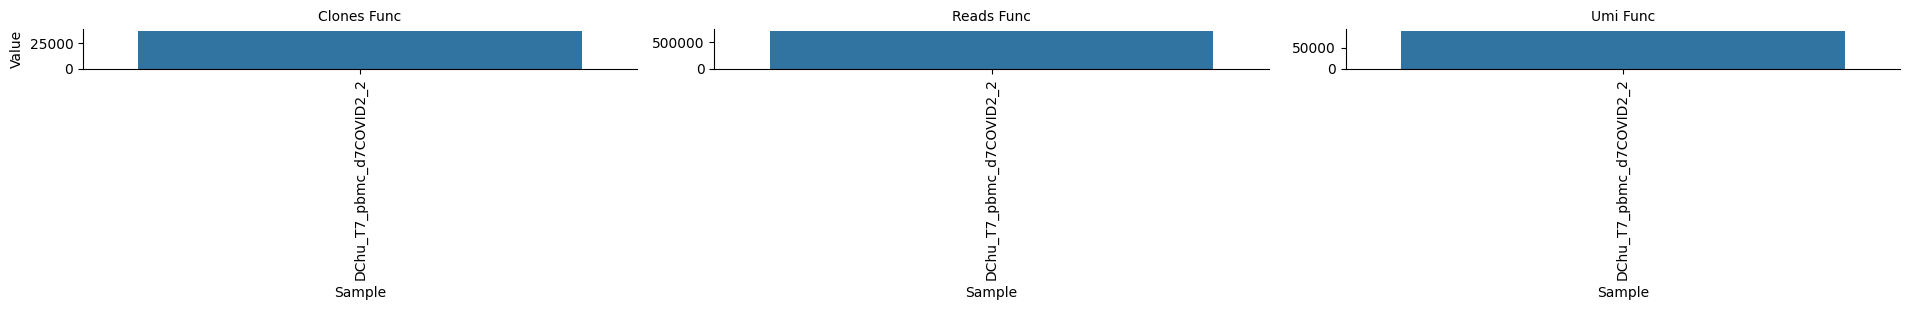

In [ ]:

rsplot.clonoset_stats(clonoset_stats_bcr,
                      properties=["clones_func", "reads_func", "umi_func"], aspect=2)

In [32]:
# Изучаем функциональную глубину молекул (UMI).
clonoset_stats_bcr.sort_values(by="umi_func")

,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,DChu_T7_pbmc_d7COVID2_2,IGH,37516,36416,24463,11953,1100,0.029321,716879,706820,10059,0.014032,90924,89665,1259,0.013847,7.88


In [33]:
# Фильтруем по продуктивности и используем UMI вместо числа сырых ридов.
total_func_umi = int(clonoset_stats_bcr["umi_func"].iloc[0])
assert total_func_umi > 1, "Функциональных UMI слишком мало"
DOWNSAMPLE_SIZE = min(10000, total_func_umi // 2)
print("Всего функциональных UMI:", total_func_umi)
print("Глубина даунсэмпла:", DOWNSAMPLE_SIZE)
func_filter = clf.Filter(functionality="f", by_umi=True)
downsample_filter = clf.Filter(functionality="f", downsample=DOWNSAMPLE_SIZE,
                               by_umi=True, seed=100)

Всего функциональных UMI: 89665
Глубина даунсэмпла: 10000


**Фильтры `clf.Filter`.** Как на семинаре: `functionality="f"` оставляет продуктивные последовательности; `top` — наиболее многочисленные клонотипы, `downsample` — случайная подвыборка по UMI, `seed` обеспечивает воспроизводимость. Здесь одна библиотека, поэтому даунсэмплирование используется для проверки **чувствительности** метрик к глубине, а не для сравнения людей.

## Filters

**`Filter` - is a special object, that may be used as a setup for Postanalysis.** You can easily create or change one and put it as an argument to other functions for individual clonoset or multi-clonoset metrics

Here is a basic default filter with all possible options:

In [34]:
# Просматриваем все настройки объекта Filter. Это пример конфигурации, не запуск анализа.
clf.Filter(name="default_filter",         # <- name of the filter
           functionality="a",             # <- functional clonotypes = clonotypes without STOP codons or out-of-frames (OOFs) in the CDR3 region, "a" = all clonotypes, "f" = leave only functional, "n" = leave only non-functional
           downsample=None,               # <- randomly downsample to this count value
           top=None,                      # <- take top-N clonotypes
           by_umi=False,                  # <- False = count by read-counts, True = count by UMI counts, if such a column exists
           mix_tails=False,               # <- True = mix all clonotypes with same counts randomly
           count_threshold=None,          # <- set minimal count value for clonotypes, others will be filtered out
           unweight=False,                # <- set count=1 to all clonotypes
           seed=None,                     # <- set seed for random processes, like downsampling and mixing tails for reproducibility
           recount_fractions=True,        # <- should you normalize all fractions to sum to 1 after filtering procedures?
           white_list=[],                 # <- a list of clonotypes, that should be left in the clonoset (the syntax for the list is below)
           black_list=[],                 # <- a list of clonotypes, that should be filtered out
           pool_clonoset_by="",           # <- combine clonotypes into one by CDR3, V or J equlity
           convert=True,                  # <- convert=False preserves all the columns of the original clonoset table. Otherwise the clonoset will be converted into VDJtools-like format for simplicity
           ignore_small_clonosets=False   # <- =True suppreses the warnings when clonoset is smaller than the given downsample or top values.
          )

Here are some examples of useful filters:

### Functional

functionality options: `a` (default) - any. `f` - only functional, `n` - only non-functional

In [35]:
# Оставляем функциональные клонотипы и используем счётчики UMI, если они доступны.
func_filter = clf.Filter(functionality="f", by_umi=True)
func_filter

**`top=4000` выбирает до 4000 клонотипов**, а не 4000 молекул. `mix_tails=True` случайно перемешивает одинаково представленные клонотипы, `seed=100` фиксирует результат.

### Top

top clonotypes by count. Recommended to mix the tails and specify the seed

In [36]:
# Как в семинаре: топ клонотипов по UMI с фиксированным seed.
top_size = min(4000, int(clonoset_stats_bcr["clones_func"].iloc[0]))
top_filter = clf.Filter(functionality="f", top=top_size, by_umi=True, mix_tails=True, seed=100)
top_filter

**Даунсэмпл.** В семинаре глубина `4500` подходила для nTreg, но не обязана подходить нашим данным. Выберем глубину исходя из числа продуктивных UMI; сравним метрики при полной и меньшей глубине.

### Downsample

Take a random sample by counts (UMI or reads). Seed is recommended to use for reproducibility.

Usually used for Diversity metrics, Convergence and other procedures, which require sample normalization

In [37]:
# Вместо 4500 выбираем глубину по размеру своего образца.
downsample_filter = clf.Filter(functionality="f", downsample=DOWNSAMPLE_SIZE, by_umi=True, seed=100)
downsample_filter

# Analysis

**Свойства CDR3.** Те же функции `repseq`, что и на семинаре: длина CDR3, вставки и свойства аминокислот. Для BCR дополнительно важно учитывать **соматические гипермутации (SHM)**. Межвозрастных сравнений здесь нет.

## CDR3 properties

Calculates different properties for CDR3 region. In this case we passed `func_filter` to make calculations only for 'functional' clonotypes

In [38]:
# Та же функция repseq для CDR3, что в семинаре.
cdr3_properties = stats.calc_cdr3_properties(clonosets_bcr, cl_filter=func_filter, cpu=1)
cdr3_properties

Using 1 core
CalcCDR3aaProperties |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,DChu_T7_pbmc_d7COVID2_2,IGH,54.231462,13.003446,0.01074,0.000027,-1.059624,-6.294754,-0.087972,-0.14233,...,5.413195,18.224631,4.493749,17.356104,5.158863,18.265454,0.276266,0.930388,0.616651,0.078671


## Тут можно в табличке посмотреть какие у нас CDR бывают.

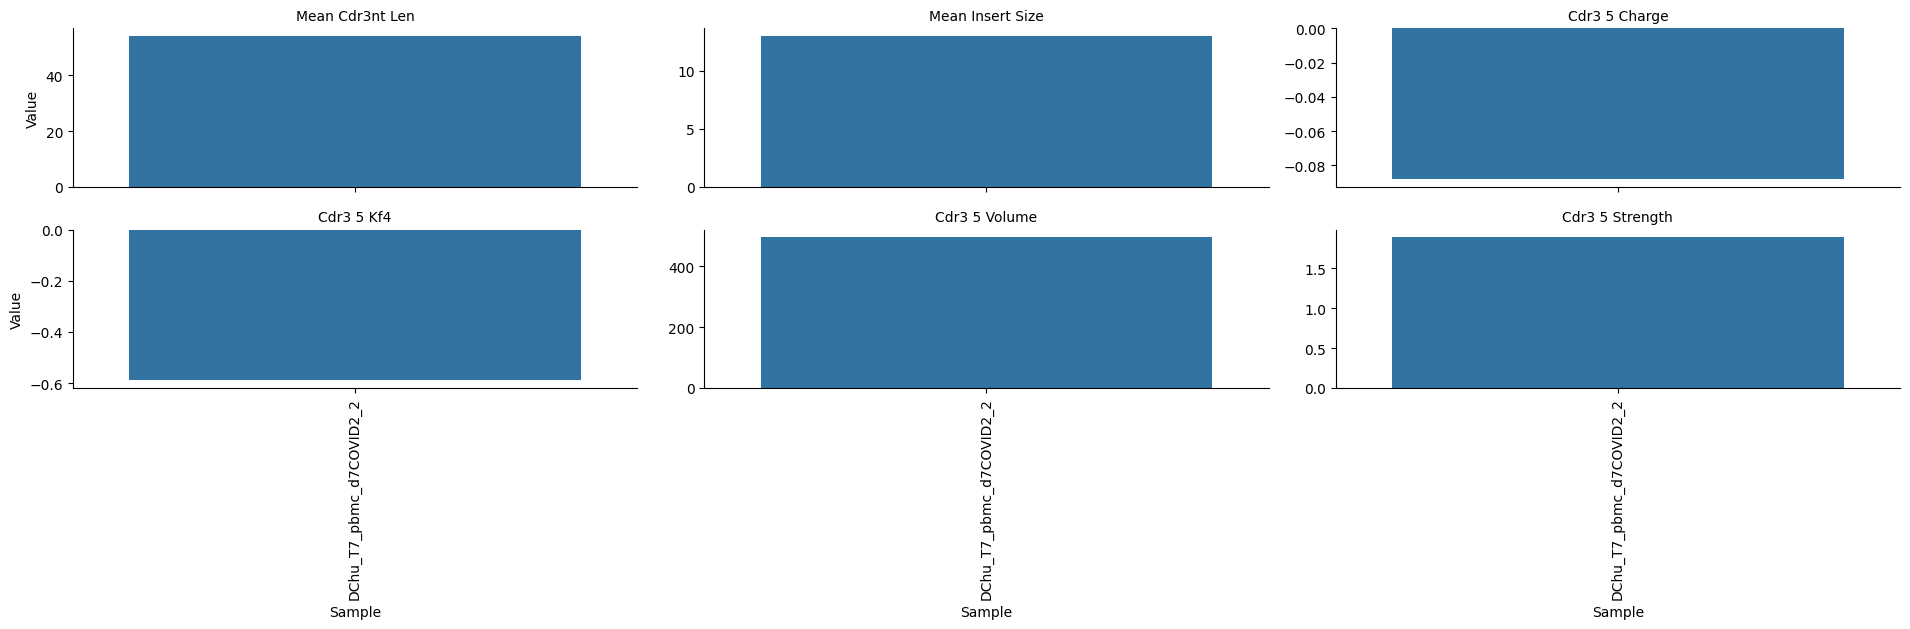

In [ ]:

rsplot.cdr3aa_stats(cdr3_properties, properties=None, height=3.2, aspect=2)

In [42]:
# Записываем рассчитанные свойства CDR3 в CSV для повторного использования.
cdr3_properties.to_csv(os.path.join(WORKING_DIR, "cdr3_properties.csv"), index=False)

Cтроим распределение **одного** IGH-репертуара. `seq_type="aa"` — длина CDR3 в аминокислотах, `count_by_freq=True` — относительная частота.

## CDR3len distributions

In [ ]:

cdr3_len_distribs = stats.cdr3_length_distributions(
    clonosets_bcr, cl_filter=func_filter, cpu=1, count_by_freq=True,
    seq_type="aa", table="long", zero_fill=True, verbose=True,
    drop_small_samples=False)
cdr3_len_distribs

Using 1 core
CalcCDR3LengthDistribution |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,DChu_T7_pbmc_d7COVID2_2,IGH,6,0.000357
1,DChu_T7_pbmc_d7COVID2_2,IGH,7,0.002309
2,DChu_T7_pbmc_d7COVID2_2,IGH,8,0.004517
3,DChu_T7_pbmc_d7COVID2_2,IGH,9,0.004004
4,DChu_T7_pbmc_d7COVID2_2,IGH,10,0.007316
5,DChu_T7_pbmc_d7COVID2_2,IGH,11,0.018123
6,DChu_T7_pbmc_d7COVID2_2,IGH,12,0.022863
7,DChu_T7_pbmc_d7COVID2_2,IGH,13,0.046696
8,DChu_T7_pbmc_d7COVID2_2,IGH,14,0.059800
9,DChu_T7_pbmc_d7COVID2_2,IGH,15,0.073172


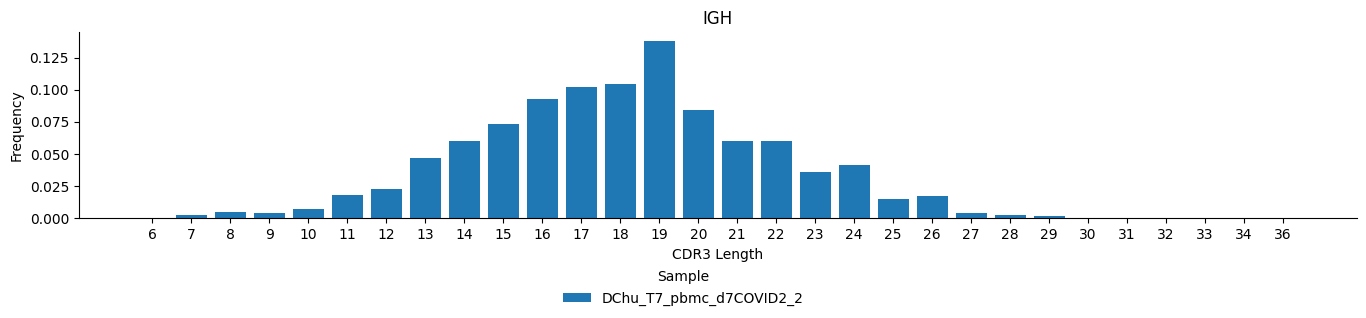

In [44]:
# Показываем распределения длин для отдельных образцов без разбиения по группам.
rsplot.cdr3_length_distributions(cdr3_len_distribs)

## Тут наглядно результаты VDJ рекомбинации - разной длины вариабельные фрагменты и даже какое-то распределение появляется

 Анализируем **IGHV/IGHJ** вместо TRBV/TRBJ. 

## Segment usage

### V-usage

In [45]:
# В исходном семинаре — V-usage для TRB; здесь IGHV.
v_usage = stats.calc_segment_usage(clonosets_bcr, segment="v", cl_filter=func_filter, table="long", cpu=1)
v_usage

Using 1 core
CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,v,usage
0,DChu_T7_pbmc_d7COVID2_2,IGH,IGHV1-17,0.000011
1,DChu_T7_pbmc_d7COVID2_2,IGH,IGHV1-18,0.065845
2,DChu_T7_pbmc_d7COVID2_2,IGH,IGHV1-2,0.010684
3,DChu_T7_pbmc_d7COVID2_2,IGH,IGHV1-24,0.003837
4,DChu_T7_pbmc_d7COVID2_2,IGH,IGHV1-3,0.020298
5,DChu_T7_pbmc_d7COVID2_2,IGH,IGHV1-45,0.000368
6,DChu_T7_pbmc_d7COVID2_2,IGH,IGHV1-46,0.024714
7,DChu_T7_pbmc_d7COVID2_2,IGH,IGHV1-58,0.002264
8,DChu_T7_pbmc_d7COVID2_2,IGH,IGHV1-68,0.000011
9,DChu_T7_pbmc_d7COVID2_2,IGH,IGHV1-69,0.024391


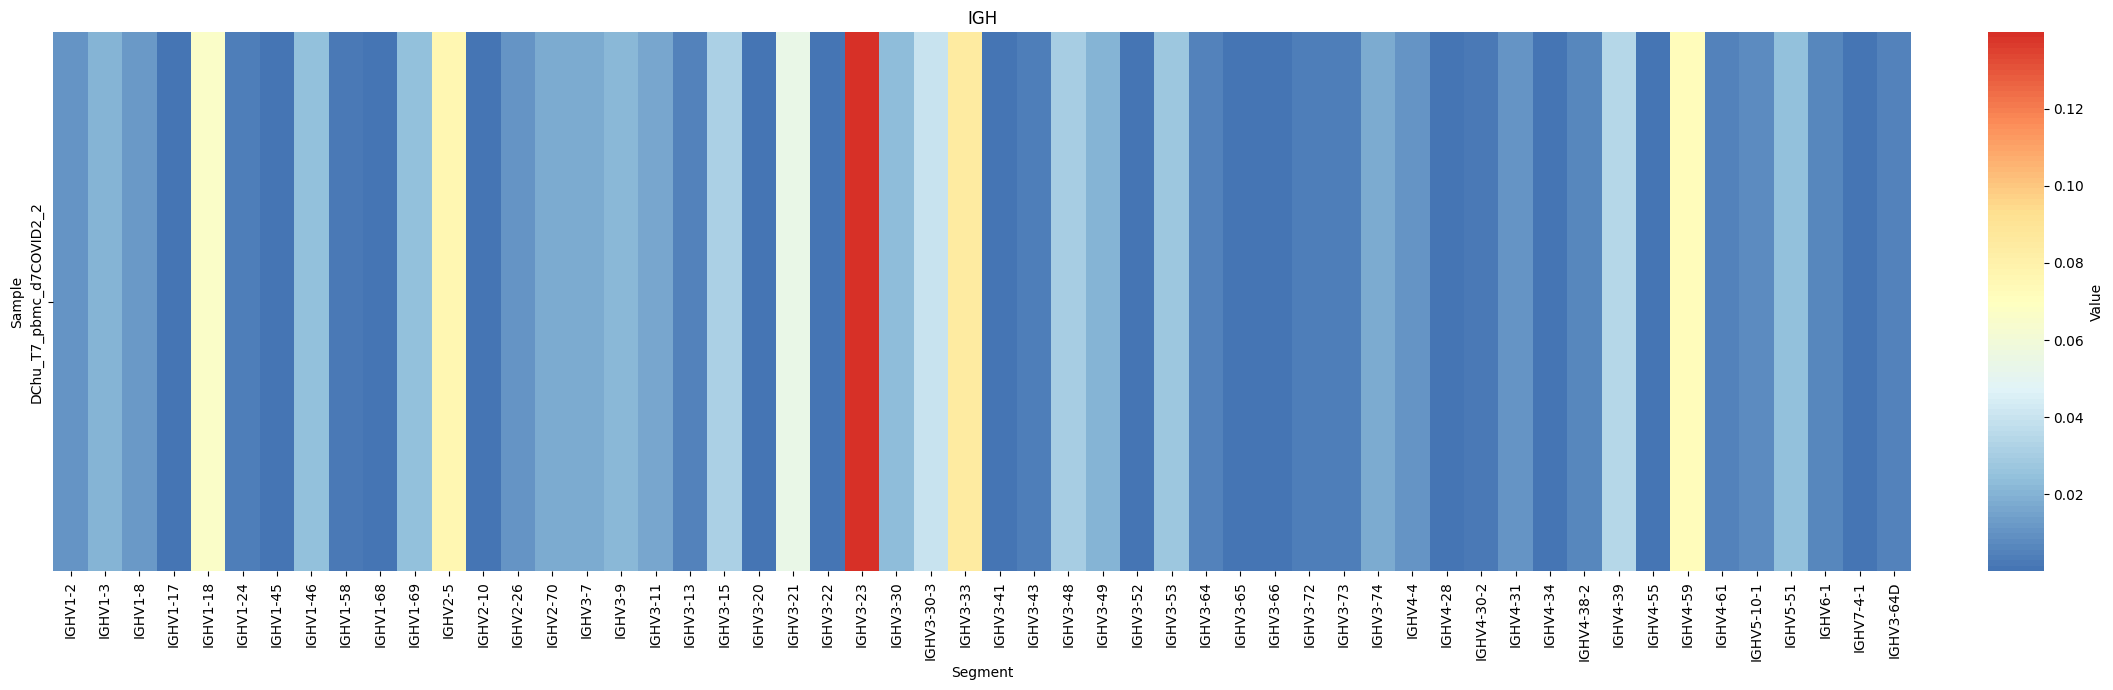

In [46]:
# Семинарский heatmap — один образец без групп.
rsplot.segment_usage(v_usage, plot_type="heatmap", height=7)

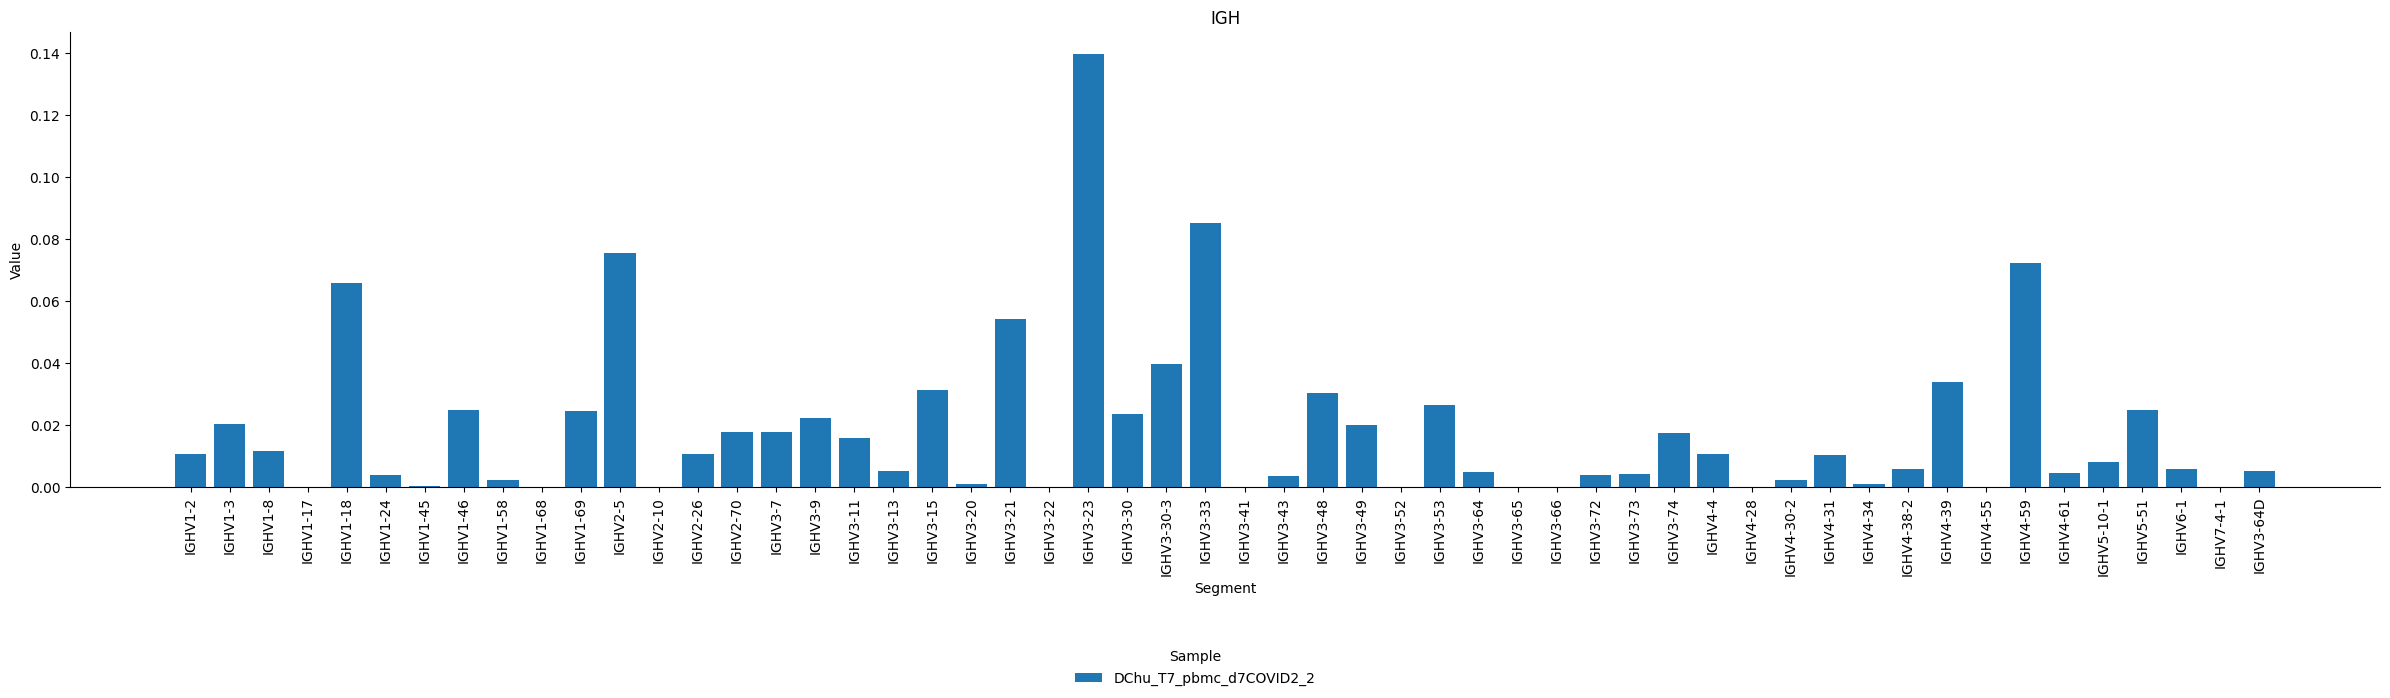

In [47]:
# Семинарский barplot частот V-генов.
rsplot.segment_usage(v_usage, plot_type="barplot", height=7)

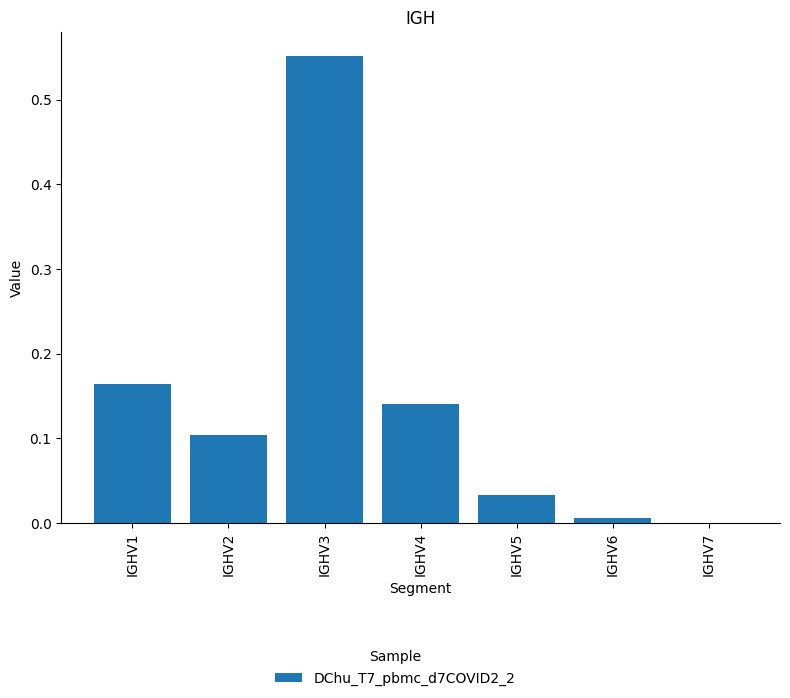

In [50]:
# Объединяем V-гены по семействам вручную
v_usage_families = v_usage.copy()

# IGHV3-64D -> IGHV3
# IGHV3-23  -> IGHV3
# IGHV4-34  -> IGHV4
v_usage_families["v"] = (
    v_usage_families["v"]
    .str.extract(r"^(IGHV\d+)", expand=False)
    .fillna("NA")
)

# Суммируем частоты внутри семейств
v_usage_families = (
    v_usage_families
    .groupby(["sample_id", "chain", "v"], as_index=False)["usage"]
    .sum()
)

# Строим график, как на семинаре
rsplot.segment_usage(
    v_usage_families,
    plot_type="barplot",
    height=7
)

## Этот код показал нам какие конкретно V гены в основном представлены в репертуаре

### J-usage

In [51]:
# Для BCR — IGHJ вместо TRBJ.
j_usage = stats.calc_segment_usage(clonosets_bcr, segment="j", cl_filter=func_filter, cpu=1)
j_usage

Using 1 core
CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,j,usage
0,DChu_T7_pbmc_d7COVID2_2,IGH,IGHJ1,0.013428
1,DChu_T7_pbmc_d7COVID2_2,IGH,IGHJ2,0.020900
2,DChu_T7_pbmc_d7COVID2_2,IGH,IGHJ3,0.137635
3,DChu_T7_pbmc_d7COVID2_2,IGH,IGHJ4,0.456934
4,DChu_T7_pbmc_d7COVID2_2,IGH,IGHJ5,0.100028
5,DChu_T7_pbmc_d7COVID2_2,IGH,IGHJ6,0.271076


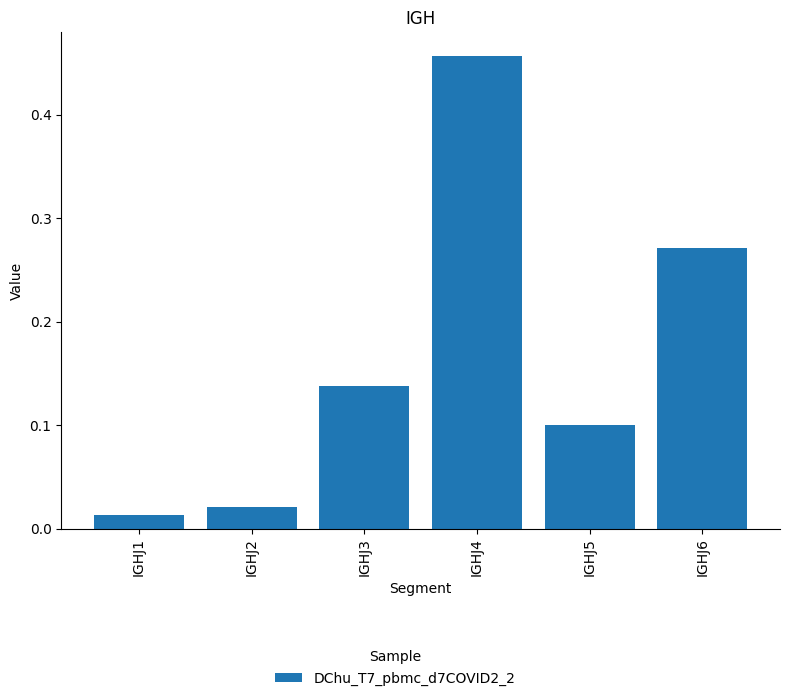

In [52]:
# Семинарская визуализация J-usage без групп.
rsplot.segment_usage(j_usage, plot_type="barplot", height=7)

### Тут тоже посмотрели на J фрагмент

### C-usage / изотипы (дополнение для BCR)

In [53]:
# C-сегменты присутствуют, если MiXCR смог аннотировать изотип.
if "allCHitsWithScore" in raw_clones.columns and raw_clones["allCHitsWithScore"].notna().any():
    c_usage = stats.calc_segment_usage(clonosets_bcr, segment="c", cl_filter=func_filter, cpu=1)
    display(c_usage)
    rsplot.segment_usage(c_usage, plot_type="barplot", height=7)
else:
    print("C-сегменты не аннотированы: пропускаем график изотипов")

Using 1 core
CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,c,usage
0,DChu_T7_pbmc_d7COVID2_2,IGH,<NA>,0.000056
1,DChu_T7_pbmc_d7COVID2_2,IGH,IGHA1,0.114638
2,DChu_T7_pbmc_d7COVID2_2,IGH,IGHA2,0.027145
3,DChu_T7_pbmc_d7COVID2_2,IGH,IGHD,0.215636
4,DChu_T7_pbmc_d7COVID2_2,IGH,IGHG1,0.186059
5,DChu_T7_pbmc_d7COVID2_2,IGH,IGHG2,0.014242
6,DChu_T7_pbmc_d7COVID2_2,IGH,IGHG3,0.032621
7,DChu_T7_pbmc_d7COVID2_2,IGH,IGHG4,0.000167
8,DChu_T7_pbmc_d7COVID2_2,IGH,IGHGP,0.000011
9,DChu_T7_pbmc_d7COVID2_2,IGH,IGHM,0.409424


### тут посмотрели клонотипы разные и заметили что в них разные иммуноглобулины - по C сегментам

## Convergence

In [54]:
# Семинарский расчёт конвергенции, теперь для IGH.
convergence = stats.calc_convergence(clonosets_bcr,
                                     cl_filter=downsample_filter,
                                     seed=42, cpu=1, verbose=True)
convergence

CalcConvergence settings: seed=42, downsample=10000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 1 core
CalcClonosetStats |##################################################| 1/1 calcultaion(s) processed
Using 1 core
CalcConvergence |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,convergence,convergence_v,convergence_vj
0,DChu_T7_pbmc_d7COVID2_2,IGH,1.01302,1.013018,1.013016


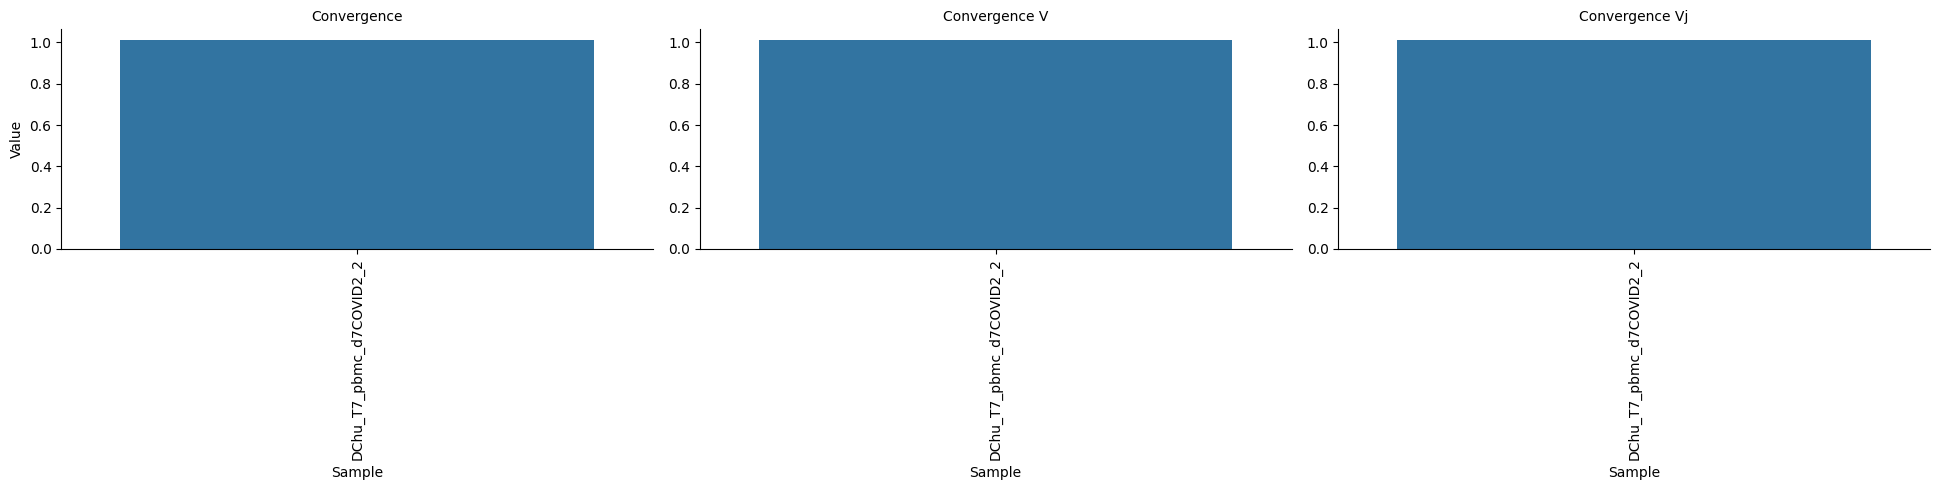

In [55]:
# Исходный график конвергенции без группового сравнения.
rsplot.convergence(convergence, height=5, aspect=1.3)

## Это значит что на одну аминокислоту одна нуклеотидная последовательность

## Diversity stats

In [56]:
# Исходный расчёт индексов; изменены лишь выборка и cpu.
diversity_stats = stats.calc_diversity_stats(clonosets_bcr,
                                            cl_filter=downsample_filter,
                                            seed=123, cpu=1, iterations=3,
                                            drop_small_samples=False, verbose=True)
diversity_stats

CalcDiversityStats settings: seed=123, downsample=10000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 1 core
CalcClonosetStats |##################################################| 1/1 calcultaion(s) processed
Using 1 core
CalcDiversityStats |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,DChu_T7_pbmc_d7COVID2_2,IGH,6229.0,0.947012,0.052988,8.274016,47683.854651,6229.0,46815.121768,0.4659,0.197303,0.000562,1778.410101,0.999438,0.0059,0.352157


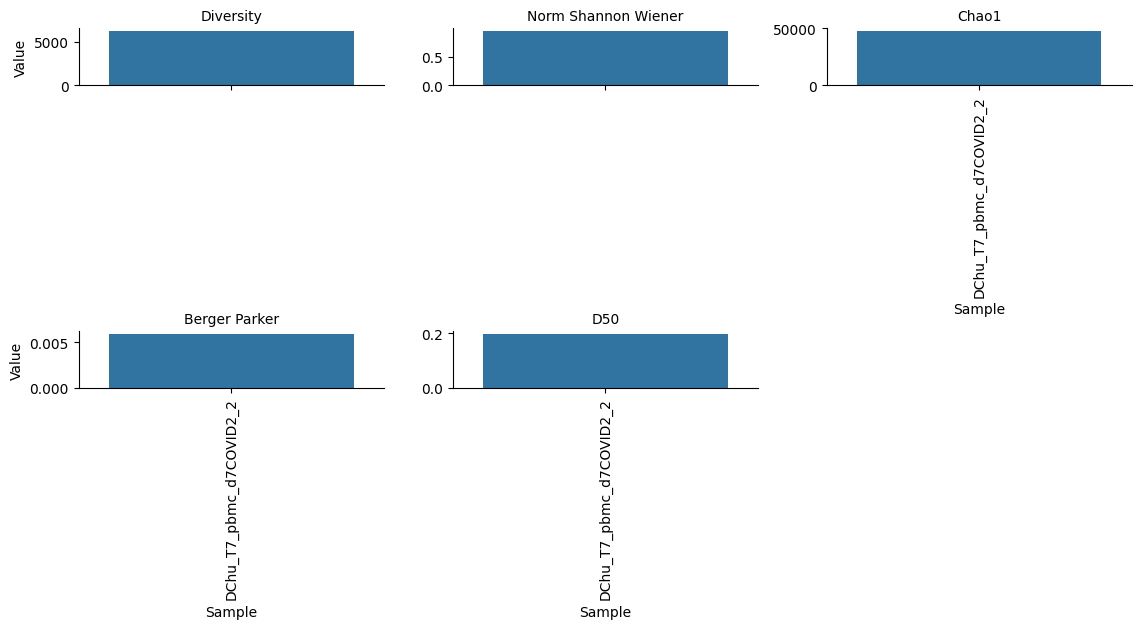

In [57]:
# График разнообразия, но без experimental_group.
rsplot.diversity_stats(diversity_stats)

## Получили метрики разнообразия - круто

### Влияние глубины: полный репертуар против даунсэмплинга

In [58]:
# Повторяем исходную функцию без даунсэмплинга.
diversity_full = stats.calc_diversity_stats(
    clonosets_bcr, cl_filter=func_filter, seed=123, cpu=1, iterations=1, verbose=True)
display(diversity_full)

columns = ["diversity", "shannon_wiener", "norm_shannon_wiener", "chao1", "clonality"]
columns = [c for c in columns if c in diversity_full.columns and c in diversity_stats.columns]
comparison = pd.DataFrame({
    "metric": columns,
    "full": [diversity_full[c].iloc[0] for c in columns],
    "downsampled": [diversity_stats[c].mean() for c in columns],
})
display(comparison)
comparison.to_csv(os.path.join(WORKING_DIR, "diversity_depth_comparison.csv"), index=False)

CalcDiversityStats: for the most honest comparison, use a filter with equal downsampling for all samples. This is preferred to top=N filters and much preferred to calculations without normalization.
CalcDiversityStats settings: seed=123, downsample=None, top=None, iterations=1
Using 1 core
CalcDiversityStats |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,DChu_T7_pbmc_d7COVID2_2,IGH,36416.0,0.887917,0.112083,9.325583,73101.501839,36416.0,81167.428485,0.727173,0.067141,0.000501,1994.658513,0.999499,0.007193,0.539796


,metric,full,downsampled
0,diversity,36416.000000,6229.000000
1,shannon_wiener,9.325583,8.274016
2,norm_shannon_wiener,0.887917,0.947012
3,chao1,73101.501839,47683.854651
4,clonality,0.112083,0.052988


## Если бы у нас было несколько образцов, нужно бы было нормировать, так как если брать подвыборку то основные метрики разнообразия сильно меняются

## Rarefaction

In [59]:
# Полная rarefaction-кривая по продуктивным UMI, без даунсэмпла.
rarefaction_points_bcr = stats.calc_rarefaction_curve(
    clonosets_bcr, cl_filter=clf.Filter(functionality="f", by_umi=True), cpu=1)
rarefaction_points_bcr

Using 1 core
CalcRarefactionPoints |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,DChu_T7_pbmc_d7COVID2_2,IGH,32,31.666667
1,DChu_T7_pbmc_d7COVID2_2,IGH,100,98.000000
2,DChu_T7_pbmc_d7COVID2_2,IGH,316,293.333333
3,DChu_T7_pbmc_d7COVID2_2,IGH,1000,856.333333
4,DChu_T7_pbmc_d7COVID2_2,IGH,3162,2346.666667
5,DChu_T7_pbmc_d7COVID2_2,IGH,10000,6207.000000
6,DChu_T7_pbmc_d7COVID2_2,IGH,31623,16467.000000
7,DChu_T7_pbmc_d7COVID2_2,IGH,89665,36416.000000


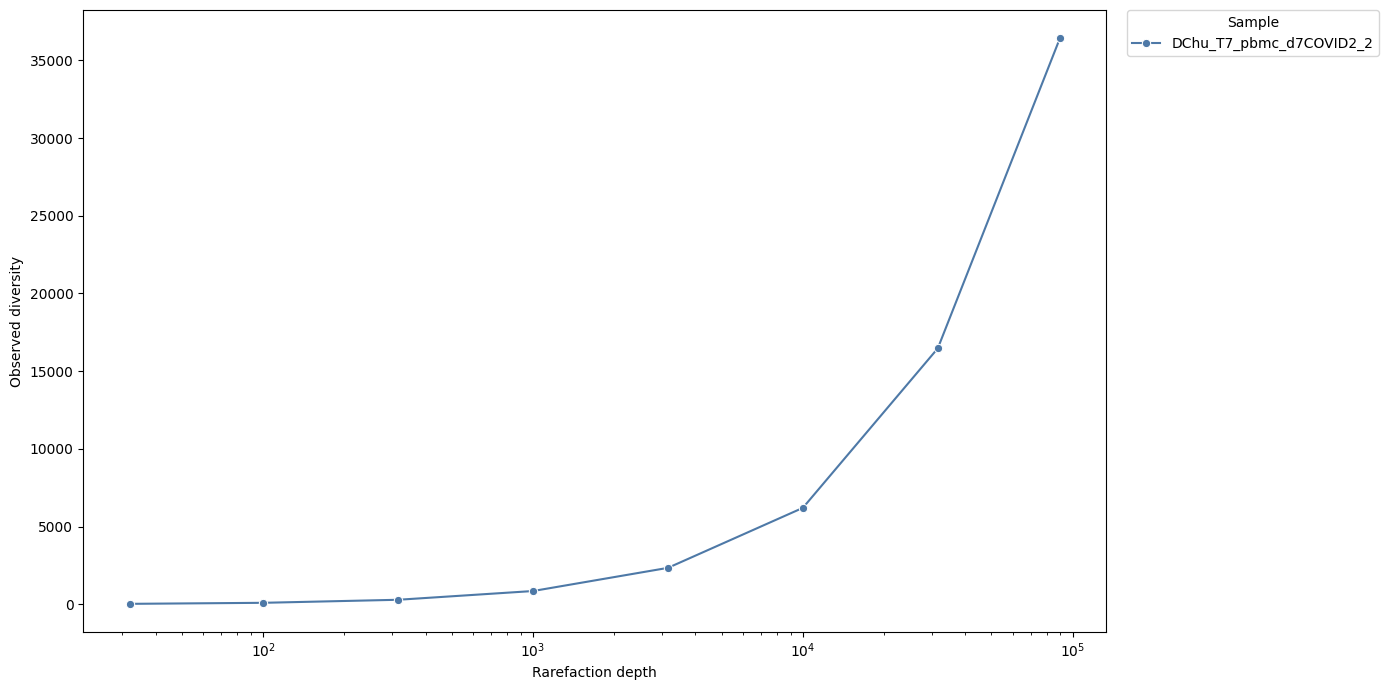

In [60]:
rsplot.rarefaction_curve(rarefaction_points_bcr, log_x=True, aspect=2, height=7)

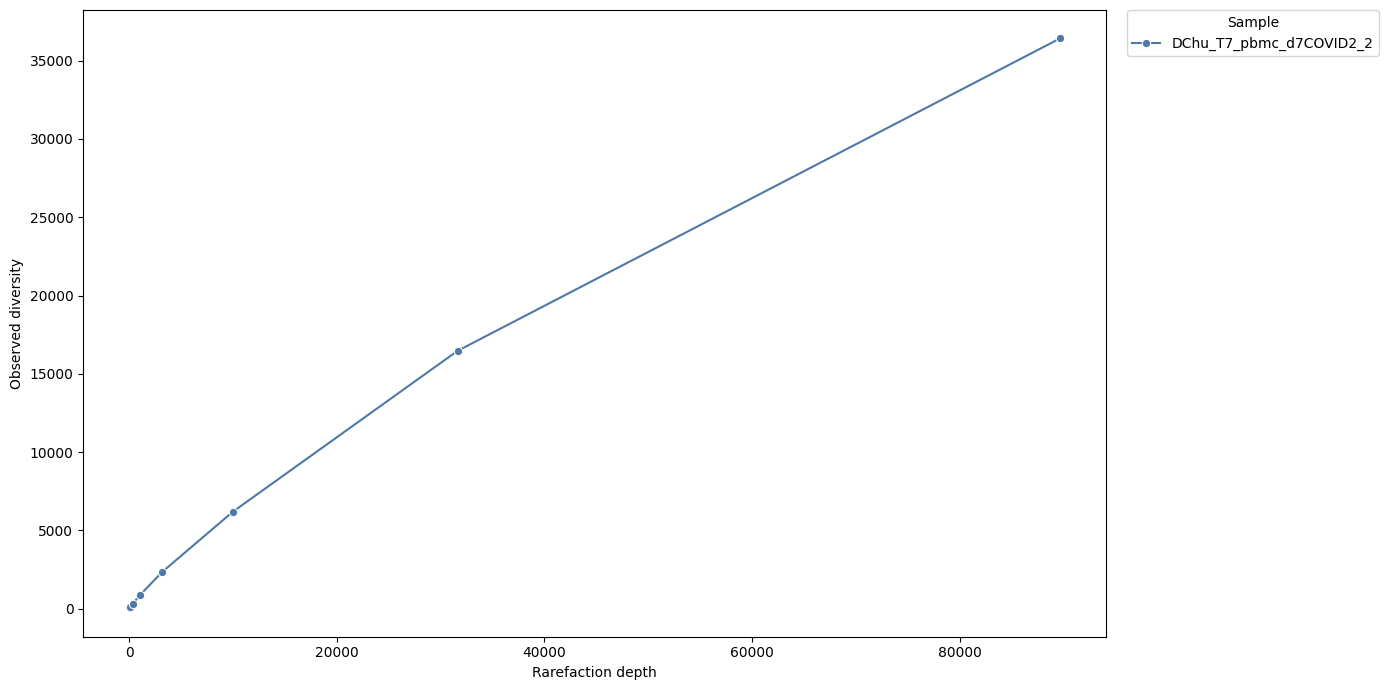

In [61]:
rsplot.rarefaction_curve(rarefaction_points_bcr, log_x=False, aspect=2, height=7)

### Тут по идее мы должны были увидеть что разнообразие выходит на плато при увеличении глубины, но это не так

## Клональное доминирование (дополнение для BCR)

Доля UMI, приходящаяся на топ-20 **продуктивных MiXCR-клонотипов**. Это доля молекул, а не число отдельных клеток или клональных линий.

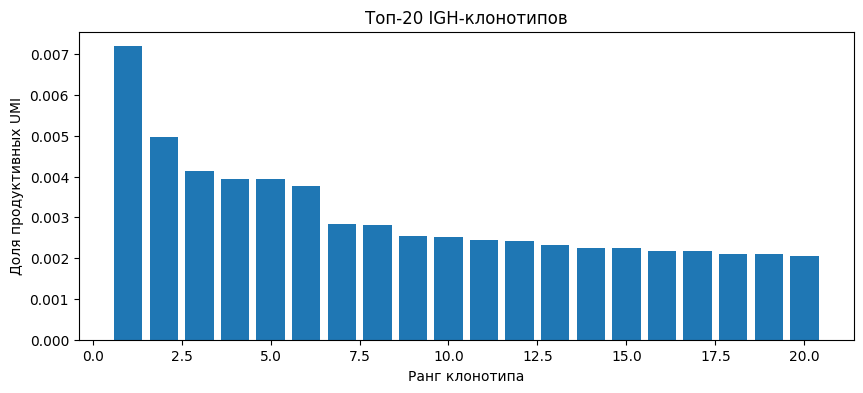

Доля UMI у топ-20: 6.10%


In [62]:
import matplotlib.pyplot as plt

productive_clones = raw_clones[~raw_clones["aaSeqCDR3"].fillna("").str.contains(r"\*|_|^$", regex=True)].copy()
top20 = productive_clones.sort_values("uniqueUMICount", ascending=False).head(20).copy()
top20["fraction_umi"] = top20["uniqueUMICount"] / productive_clones["uniqueUMICount"].sum()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, len(top20)+1), top20["fraction_umi"])
ax.set_xlabel("Ранг клонотипа")
ax.set_ylabel("Доля продуктивных UMI")
ax.set_title("Топ-20 IGH-клонотипов")
plt.show()
print("Доля UMI у топ-20:", f"{top20['fraction_umi'].sum():.2%}")

### Если у самых частых клонотипов доля всего 6 процентов, то никакого клонального доминирования скорее всего не существует

## Beta-diversity

у нас только один образец

## Clustering

### Create clusters

In [ ]:
RUN_CLUSTERING = True  
print("Кластеризация:", "включена" if RUN_CLUSTERING else "пропущена")

Кластеризация: включена


In [ ]:

if RUN_CLUSTERING:
    clusters = clustering.Clusters()
    display(clusters)

Clusters state:
  State: empty
Clonotypes: not read
Clusters: not created
Metadata: not added
Node Pgen: not calculated
ALICE: not calculated

In [ ]:

if RUN_CLUSTERING:
    clusters.read_from_clonosets_df(clonosets_bcr, cl_filter=top_filter)

Pooled 4000 clonotypes from 1 samples


In [ ]:

if RUN_CLUSTERING:
    clusters.create_clusters(overlap_type="aaV", mismatches=1)

Nodes list created: 4000 nodes
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Find neighbour clonotypes |##################################################| 584/584 tasks processed
found 1622 edges
-----------------------------
NexworkX graph created
Found 191 clusters (2 or more nodes) and 3390 single nodes. Total: 3581


In [ ]:

if RUN_CLUSTERING:
    clusters.add_metadata(metadata)

In [ ]:

if RUN_CLUSTERING:
    clusters_df = clusters.as_dataframe()
    display(clusters_df)

,cluster_no,node_id,cdr3aa,v,j,cdr3nt,sample_id,freq,count,isotype,n_neighbours,material
0,0,94,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGCCGTACTGGACTTTGGAGTGGTTATGGCTACA...,DChu_T7_pbmc_d7COVID2_2,0.001826,90,IgG1,39,PBMC
1,0,283,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,DChu_T7_pbmc_d7COVID2_2,0.000872,43,IgG1,39,PBMC
2,0,683,CARDRRTGLWSGYGYMDLW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,DChu_T7_pbmc_d7COVID2_2,0.000304,15,IgG1,36,PBMC
3,0,884,CARDRRTGVWSGYGYMDLW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGCCGTACTGGTGTTTGGAGTGGTTATGGCTACA...,DChu_T7_pbmc_d7COVID2_2,0.000162,8,IgG1,6,PBMC
4,0,186,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,DChu_T7_pbmc_d7COVID2_2,0.001177,58,IgG1,39,PBMC
...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3576,2220,CVSTYYDSSGYSDYW,IGHV3-11,IGHJ4,TGTGTGTCGACTTACTATGATAGTAGTGGTTACTCGGACTACTGG,DChu_T7_pbmc_d7COVID2_2,0.000061,3,IgM,0,PBMC
3996,3577,2246,CVTLVVTDGVAFDYW,IGHV3-74,IGHJ4,TGTGTAACTCTAGTGGTGACTGATGGGGTCGCATTTGACTACTGG,DChu_T7_pbmc_d7COVID2_2,0.000061,3,IgM,0,PBMC
3997,3578,2035,CVVSQVRW,IGHV1-8,IGHJ4,TGTGTGGTATCCCAAGTTAGGTGG,DChu_T7_pbmc_d7COVID2_2,0.000061,3,IgM,0,PBMC
3998,3579,1345,CWEIFGPW,IGHV4-39,IGHJ5,TGTTGGGAGATTTTTGGCCCCTGG,DChu_T7_pbmc_d7COVID2_2,0.000081,4,IgD,0,PBMC


In [79]:
# Характеристики кластеров.
if RUN_CLUSTERING:
    cluster_properties = clusters.properties()
    display(cluster_properties)

Using all available worker processes by default. Set cpu=1 or another integer to change this.
Calculating cluster properties |##################################################| 3581/3581 clusters processed


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,46,797,3941,4,0.770048,2.369565,CARDRRTGLWSGYGYMDVW,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,IGHV3-33,IGHJ6
1,1,cluster_1,23,102,457,6,0.403162,4.217391,CAKLQGIFWLWQPNRAGGADYW,TGTGCGAAACTTCAGGGAATATTTTGGTTGTGGCAACCCAACCGGG...,IGHV3-30,IGHJ4
2,2,cluster_2,13,38,697,3,0.487179,2.769231,CARFVRGAFPPYYYYMDVW,TGTGCGAGATTTGTACGTGGAGCTTTTCCCCCCTACTACTACTACA...,IGHV1-18,IGHJ6
3,3,cluster_3,11,53,502,2,0.963636,1.272727,CAHRPGIALVGAGAFRFDPW,TGTGCACACAGGCCGGGTATAGCACTGGTTGGTGCTGGTGCGTTCC...,IGHV2-5,IGHJ5
4,4,cluster_4,11,31,145,3,0.563636,2.454545,CARSPRRFDFWSGFYSYYFDYW,TGTGCGAGATCCCCCCGGCGTTTCGATTTTTGGAGTGGTTTTTATT...,IGHV3-21,IGHJ4
...,...,...,...,...,...,...,...,...,...,...,...,...
3576,3576,cluster_3576,1,0,3,0,0.000000,0.000000,CVSTYYDSSGYSDYW,TGTGTGTCGACTTACTATGATAGTAGTGGTTACTCGGACTACTGG,IGHV3-11,IGHJ4
3577,3577,cluster_3577,1,0,3,0,0.000000,0.000000,CVTLVVTDGVAFDYW,TGTGTAACTCTAGTGGTGACTGATGGGGTCGCATTTGACTACTGG,IGHV3-74,IGHJ4
3578,3578,cluster_3578,1,0,3,0,0.000000,0.000000,CVVSQVRW,TGTGTGGTATCCCAAGTTAGGTGG,IGHV1-8,IGHJ4
3579,3579,cluster_3579,1,0,4,0,0.000000,0.000000,CWEIFGPW,TGTTGGGAGATTTTTGGCCCCTGG,IGHV4-39,IGHJ5


In [80]:
# Вместо TCR-специфичного фильтра TRBV/TRBJ показываем первые BCR-кластеры.
if RUN_CLUSTERING:
    display(cluster_properties.head(10))

,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,46,797,3941,4,0.770048,2.369565,CARDRRTGLWSGYGYMDVW,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,IGHV3-33,IGHJ6
1,1,cluster_1,23,102,457,6,0.403162,4.217391,CAKLQGIFWLWQPNRAGGADYW,TGTGCGAAACTTCAGGGAATATTTTGGTTGTGGCAACCCAACCGGG...,IGHV3-30,IGHJ4
2,2,cluster_2,13,38,697,3,0.487179,2.769231,CARFVRGAFPPYYYYMDVW,TGTGCGAGATTTGTACGTGGAGCTTTTCCCCCCTACTACTACTACA...,IGHV1-18,IGHJ6
3,3,cluster_3,11,53,502,2,0.963636,1.272727,CAHRPGIALVGAGAFRFDPW,TGTGCACACAGGCCGGGTATAGCACTGGTTGGTGCTGGTGCGTTCC...,IGHV2-5,IGHJ5
4,4,cluster_4,11,31,145,3,0.563636,2.454545,CARSPRRFDFWSGFYSYYFDYW,TGTGCGAGATCCCCCCGGCGTTTCGATTTTTGGAGTGGTTTTTATT...,IGHV3-21,IGHJ4
5,5,cluster_5,11,26,330,4,0.472727,3.272727,CARTQKEVTIFGTFYYAMDVW,TGTGCACGGACCCAAAAAGAGGTTACGATTTTTGGAACCTTCTACT...,IGHV2-26,IGHJ6
6,6,cluster_6,10,21,433,3,0.466667,2.700000,CAHRSGIAVAGTGVFDYW,TGTGCACACAGATCCGGTATAGCAGTGGCTGGTACGGGGGTTTTTG...,IGHV2-5,IGHJ4
7,7,cluster_7,10,41,148,2,0.911111,1.500000,CARENSYYDFWASRGGFRYYMDVW,TGTGCGAGAGAAAATTCCTATTACGATTTTTGGGCCTCCCGTGGGG...,IGHV4-59,IGHJ6
8,8,cluster_8,9,36,628,1,1.000000,1.000000,CARDPNYDFWSGGDMNVW,TGTGCGAGAGACCCCAATTACGATTTTTGGAGTGGAGGGGACATGA...,IGHV3-21,IGHJ6
9,9,cluster_9,9,34,153,2,0.944444,1.333333,CATKYCSGGRCSDFEYW,TGTGCGACAAAATATTGTAGTGGCGGTCGCTGCTCGGATTTTGAAT...,IGHV4-4,IGHJ4


In [81]:
# Сводная информация, как в исходнике.
if RUN_CLUSTERING:
    display(clusters)

Clusters state:
  Completed: clonotypes read, clusters created, metadata added
Clonotypes:
    source: clonosets_df
    clonotypes: 4000
    samples: 1
    input_samples: 1
    filter:
      name: default_filter
      functionality: f
      downsample_size: None
      top: 4000
      by_umi: True
      mix_tails: True
      seed: 100
      count_threshold: None
      unweight: False
      recount_fractions: True
      white_list: []
      black_list: []
      pool_by: 
      convert: True
      ignore_small_clonosets: False
      retain_alleles: False
Graph: 4000 nodes and 1622 edges
Clusters: 191 clusters (2 or more nodes) and 3390 single nodes. Total: 3581
Clustering parameters:
    method: mismatches
    overlap_type: aaV
    mismatches: 1
Metadata columns: material
Node Pgen: not calculated
ALICE: not calculated

**Визуализация кластеров.** Вершины — близкие IGH-клонотипы, рёбра — заданное сходство. Для одного образца цвет по возрастным группам не имеет смысла.

### Plot clusters

In [82]:
# Вместо фиксированных ID 20–29 выбираем первые пять существующих кластеров.
if RUN_CLUSTERING and len(cluster_properties):
    clusters.plot_cluster(list(cluster_properties.index[:5]),
                          label="count", log_scaled=False, size="count", linear_scale=50)

### С кластеризацией не получилось, потому что нужно больше образцов, 4000 кластеров на один образец это плохо, нужно ещё данные

## Выводы

В этом одном образце очень много редких последовательностей и сильное разнообразие

 CDR3, V и J сегменты разные по длине и ссотаву. Наиболее распространены V-гены семейства IGHV3 и J-ген IGHJ4.

В репертуаре есть иммуноглобулины IgM, IgD, IgG и IgA.

От размера выборки очень зависит разнообразие и оно не выщло на плато - следовательно нужны ещё образцы

Кластеризация выявила какие-то кластеры, но опять таки нужно больше образцов